# 04 — Filtros Convolucionais Manuais

Aplicação manual dos três filtros convolucionais $3 \times 3$ sobre uma imagem representativa do conjunto de dados (`PN00-1_seizure01_ictal.png`):

- **Kernel de suavização:** $\frac{1}{9}\begin{bmatrix} 1 & 1 & 1 \\ 1 & 1 & 1 \\ 1 & 1 & 1 \end{bmatrix}$
- **Kernel detector de bordas:** $\begin{bmatrix} -1 & -1 & -1 \\ -1 & 8 & -1 \\ -1 & -1 & -1 \end{bmatrix}$
- **Filtro Sobel:** $\begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}$

In [1]:
import sys
from pathlib import Path
import numpy as np
from PIL import Image

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing.conv_filters import (
    apply_smoothing_filter,
    apply_edge_detector_filter,
    apply_sobel_filter,
)

%matplotlib inline
import matplotlib.pyplot as plt

# 1. Selecao da imagem representativa
SAMPLE_PATH = PROJECT_ROOT / 'data' / 'processed' / 'mod_spectograms' / 'PN00' / 'PN00-1_seizure01_ictal.png'
img_orig = np.array(Image.open(SAMPLE_PATH).convert('RGB'), dtype=np.uint8)

# 2. Aplicacao manual dos filtros convolucionais
img_smooth = apply_smoothing_filter(img_orig)
img_edges  = apply_edge_detector_filter(img_orig, mode='abs')
img_sobel  = apply_sobel_filter(img_orig, mode='abs')

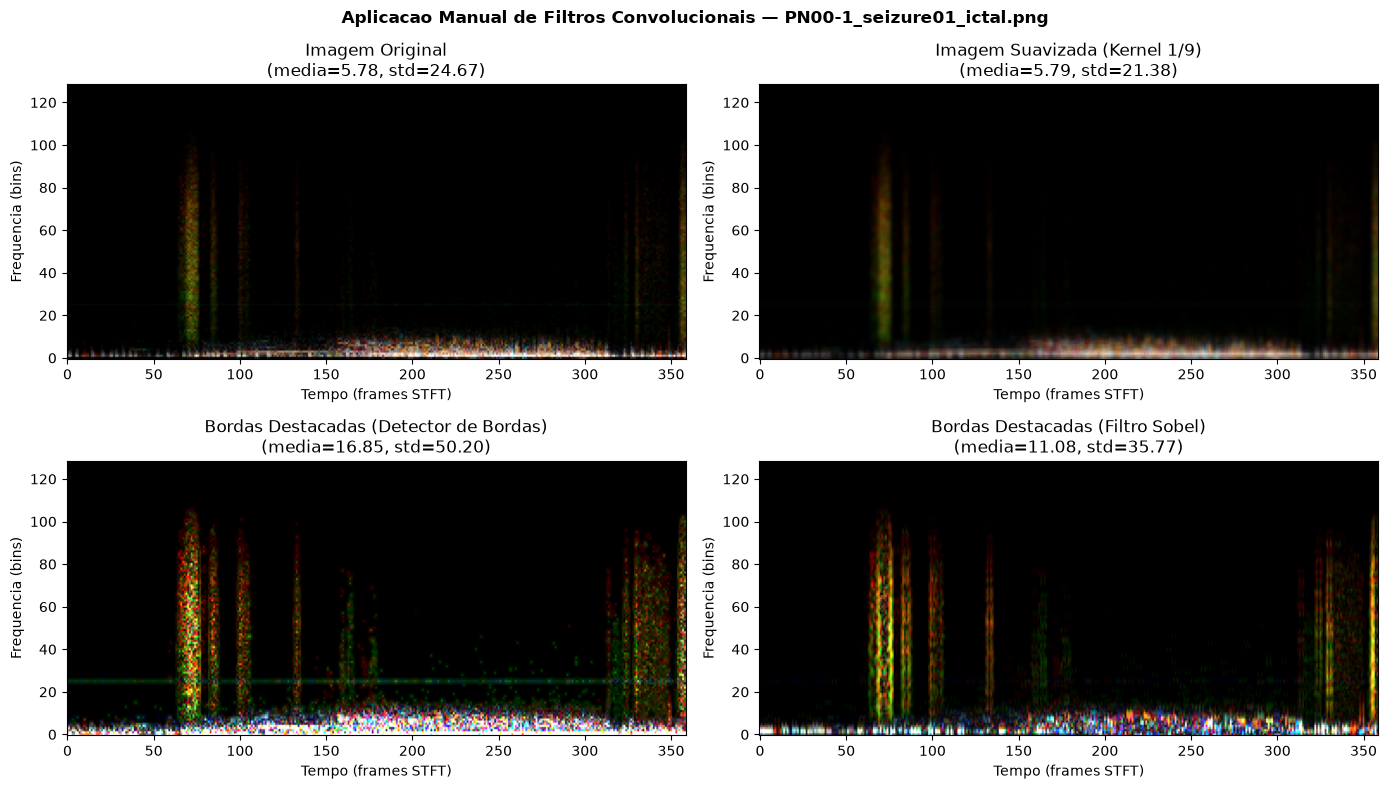

In [2]:
# 3. Visualizacao: Imagem Original, Imagem Suavizada e Imagens com Bordas Destacadas
resultados = [
    ('Imagem Original', img_orig),
    ('Imagem Suavizada (Kernel 1/9)', img_smooth),
    ('Bordas Destacadas (Detector de Bordas)', img_edges),
    ('Bordas Destacadas (Filtro Sobel)', img_sobel),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (titulo, img) in zip(axes.flat, resultados):
    ax.imshow(img, aspect='auto', origin='lower')
    ax.set_title(f'{titulo}\n(media={img.mean():.2f}, std={img.std():.2f})')
    ax.set_xlabel('Tempo (frames STFT)')
    ax.set_ylabel('Frequencia (bins)')

plt.suptitle(f'Aplicacao Manual de Filtros Convolucionais — {SAMPLE_PATH.name}', fontweight='bold')
plt.tight_layout()
plt.show()

## Análise Comparativa dos Resultados

- **Imagem Original (`média = 5.78`, `std = 24.67`):** Apresenta regiões localizadas de energia espectral (descargas da fase *ictal*) sobre um fundo predominantemente escuro.
- **Imagem Suavizada — Kernel de Suavização (`média = 5.79`, `std = 21.38`):** Por calcular a média simples da vizinhança $3 \times 3$, atua como um filtro **passa-baixas**. Conserva o brilho médio da imagem, reduz o desvio padrão (atenuando picos isolados e ruídos pontuais) e deixa as transições entre pixels vizinhos mais homogêneas e borradas.
- **Imagem com Bordas Destacadas — Kernel Detector de Bordas (`média = 16.85`, `std = 50.20`):** Como a soma dos pesos do kernel é zero ($8 - 8 = 0$), regiões uniformes são zeradas e apenas mudanças bruscas de intensidade em **todas as direções** (horizontais, verticais e diagonais) são fortemente amplificadas, destacando todo o contorno das regiões de atividade epiléptica.
- **Imagem com Bordas Destacadas — Filtro Sobel (`média = 11.08`, `std = 35.77`):** Calcula o gradiente na direção horizontal ($x = \text{tempo}$) combinado com suavização vertical ($y = \text{frequência}$). Com isso, destaca seletivamente **bordas verticais** (início e fim de pulsos/descargas ao longo do tempo), gerando contornos menos ruidosos que o detector de bordas isotrópico.